# 00 · A tour of the Massive data store

Everything downloaded by `massive-subspace-stream` lives under `~/market_data/massive` and is
read through one object: **`Store`**. This notebook shows what is stored and the basic query
patterns that the other notebooks build on.

| Notebook | Topic |
|---|---|
| **00** | the store: coverage, datasets, calendar, pandas vs polars, lazy scans |
| 01 | daily bars, price adjustment, point-in-time universe |
| 02 | minute bars and intraday patterns |
| 03 | trades and quotes (tick data) |
| 04 | reference data, fundamentals, short data, news |
| 05 | real-time data from the stream service |

In [1]:
import polars as pl
from massive_subspace_stream import Store
from subspace_probe import human_bytes, style, timed

style()
pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(140)
pl.Config.set_fmt_str_lengths(60)

store = Store()  # default root: ~/market_data/massive (override with Store(root=...))
store

Store(root='/Users/yuriturygin/market_data/massive')

## What is stored

`coverage()` reads the catalog (a small SQLite file), so it is instant. It is the first thing to
check before an analysis: one row per dataset with its date range, rows and size on disk.

In [2]:
cov = store.coverage().with_columns(
    pl.col("bytes").map_elements(human_bytes, return_dtype=pl.String).alias("size")
).select("dataset", "partitions", "first", "last", "rows", "size").sort("dataset")
print(f"total on disk: {human_bytes(store.coverage()['bytes'].sum())}")
cov

total on disk: 83.8 GB


dataset,partitions,first,last,rows,size
str,i64,str,str,i64,str
"""balance_sheets""",17,"""2010""","""2026""",247552,"""19.6 MB"""
"""bars_day""",5823,"""2003-09-10""","""2026-10-30""",50159183,"""918.2 MB"""
"""bars_minute""",5823,"""2003-09-10""","""2026-10-30""",7602752965,"""82.3 GB"""
"""cash_flow_statements""",17,"""2010""","""2026""",423815,"""27.8 MB"""
"""conditions""",1,"""all""","""all""",94,"""6.0 KB"""
"""dividends""",1,"""all""","""all""",731840,"""34.6 MB"""
"""exchanges""",1,"""all""","""all""",27,"""4.7 KB"""
"""float""",1,"""all""","""all""",6976,"""77.2 KB"""
"""income_statements""",17,"""2010""","""2026""",432714,"""31.1 MB"""


`datasets()` lists everything the package *can* store (including what has not been
downloaded yet), with a short description.

In [3]:
pl.DataFrame({"dataset": list(store.datasets()), "description": list(store.datasets().values())})

dataset,description
str,str
"""bars_day""","""Daily OHLCV bars, all US-listed tickers"""
"""bars_minute""","""1-minute OHLCV bars incl. extended hours"""
"""trades""","""Every SIP trade (about 3 GB/day compressed)"""
"""quotes""","""Every SIP NBBO quote (about 9 GB/day compressed)"""
"""tickers""","""All stock tickers, active and delisted, with FIGI/CIK identi…"
"""ticker_types""","""Ticker type codes (CS, ETF, ADRC, ...)"""
"""exchanges""","""Exchange and TRF ids used in trades/quotes"""
"""conditions""","""Trade/quote condition codes with names and how each affects …"
"""market_holidays""","""Upcoming market holidays and early closes (history accumulat…"


## Bars: the main query

`store.bars(tickers, start, end, freq, adjust, session, backend)` covers daily (`"1d"`) and
minute (`"1min"`) bars. Tickers can be one string, a list, or `None` for every ticker.

Conventions worth remembering:
- prices are stored **as traded** (unadjusted). Pass `adjust="splits"` or `adjust="all"`
  (splits + dividends) for continuous series.
- `timestamp` is the bar start in **UTC**; `date` is the US/Eastern trading date.
- delisted tickers are kept, so there is no survivorship bias.

In [4]:
daily = store.bars(["AAPL", "MSFT", "NVDA"], start="2026-10-26", end="2026-10-30")
daily

ticker,date,timestamp,open,high,low,close,volume,transactions
str,date,"datetime[ns, UTC]",f64,f64,f64,f64,f64,i64
"""AAPL""",2026-10-26,2026-10-26 04:00:00 UTC,343.92,347.09,341.03,343.91,4.2744e7,699113
"""AAPL""",2026-10-27,2026-10-27 04:00:00 UTC,343.165,347.78,342.39,347.1,3.9984e7,632426
"""AAPL""",2026-10-28,2026-10-28 04:00:00 UTC,346.92,347.18,343.52,343.83,3.5714e7,600595
"""AAPL""",2026-10-29,2026-10-29 04:00:00 UTC,348.0,351.43,347.3,348.91,4.2582e7,736010
"""AAPL""",2026-10-30,2026-10-30 04:00:00 UTC,346.715,349.19,334.35,344.63,6.7842e7,992293
"""MSFT""",2026-10-26,2026-10-26 04:00:00 UTC,527.4,533.25,521.69,532.6,1.9021e7,451369
"""MSFT""",2026-10-27,2026-10-27 04:00:00 UTC,532.35,534.7,528.33,531.33,1.9532e7,389941
"""MSFT""",2026-10-28,2026-10-28 04:00:00 UTC,531.82,535.0,526.135,531.01,2.8594e7,695415
"""MSFT""",2026-10-29,2026-10-29 04:00:00 UTC,540.22,541.29,519.56,530.14,3.9333e7,840694


The default output is a **polars** DataFrame. Every method also takes `backend="pandas"`:

In [5]:
pdf = store.bars("SPY", start="2026-10-26", end="2026-10-30", backend="pandas")
print(type(pdf))
pdf.set_index("date")[["open", "high", "low", "close", "volume"]]

<class 'pandas.DataFrame'>


,open,high,low,close,volume
date,,,,,
2026-10-26,762.25,767.73,761.63,765.37,3.173780e+07
2026-10-27,767.34,771.14,765.21,769.66,2.863166e+07
2026-10-28,771.43,773.36,769.24,772.31,3.013380e+07
2026-10-29,768.79,770.76,766.62,769.36,4.029958e+07
2026-10-30,761.38,761.46,750.36,755.72,7.769648e+07


Minute bars use the same call. `session="regular"` keeps exchange hours only (early closes
included); `"extended"` keeps pre- and post-market; `"all"` keeps both.

In [6]:
spy_min = store.bars("SPY", start="2026-10-30", end="2026-10-30", freq="1min")
for session in ("all", "regular", "extended"):
    n = store.bars("SPY", start="2026-10-30", end="2026-10-30", freq="1min", session=session).height
    print(f"{session:>8}: {n:4d} bars")
spy_min.head()

     all:  943 bars
 regular:  390 bars
extended:  553 bars


ticker,date,timestamp,open,high,low,close,volume,transactions
str,date,"datetime[ns, UTC]",f64,f64,f64,f64,f64,i64
"""SPY""",2026-10-30,2026-10-30 08:00:00 UTC,762.6,763.47,762.19,762.37,6007.687038,604
"""SPY""",2026-10-30,2026-10-30 08:01:00 UTC,762.25,763.62,762.08,762.16,25765.383933,769
"""SPY""",2026-10-30,2026-10-30 08:02:00 UTC,762.22,763.03,762.1,762.96,4627.0,153
"""SPY""",2026-10-30,2026-10-30 08:03:00 UTC,762.9,763.65,762.03,763.1,23384.0,945
"""SPY""",2026-10-30,2026-10-30 08:04:00 UTC,763.0,763.2,762.07,762.135,3063.358299,104


## Trading calendar

`trading_days()` and `sessions()` use the NYSE calendar, including holidays and early closes
(for example the day after Thanksgiving closes at 13:00 New York time).

In [7]:
days_2026 = store.trading_days("2026-01-01", "2026-12-31")
print(f"{len(days_2026)} NYSE sessions in 2026; first {days_2026[0]}, last {days_2026[-1]}")

store.sessions("2024-11-26", "2024-12-03").with_columns(
    pl.col("market_open").dt.convert_time_zone("America/New_York").alias("open_ny"),
    pl.col("market_close").dt.convert_time_zone("America/New_York").alias("close_ny"),
).select("date", "open_ny", "close_ny")

251 NYSE sessions in 2026; first 2026-01-02, last 2026-12-31


date,open_ny,close_ny
date,"datetime[ns, America/New_York]","datetime[ns, America/New_York]"
2024-11-26,2024-11-26 09:30:00 EST,2024-11-26 16:00:00 EST
2024-11-27,2024-11-27 09:30:00 EST,2024-11-27 16:00:00 EST
2024-11-29,2024-11-29 09:30:00 EST,2024-11-29 13:00:00 EST
2024-12-02,2024-12-02 09:30:00 EST,2024-12-02 16:00:00 EST
2024-12-03,2024-12-03 09:30:00 EST,2024-12-03 16:00:00 EST


## Lazy queries over everything

For questions across the whole market, `lazy=True` (or `store.scan(dataset)`) returns a polars
`LazyFrame`. Nothing is read until `.collect()`, and polars only reads the columns and row
groups it needs. Files are sorted by ticker, so single-ticker reads skip most of each file.

Example: the ten most traded stocks by dollar volume on the latest day, from 1.9M minute bars.

In [8]:
latest = store.coverage().filter(pl.col("dataset") == "bars_minute")["last"].item()
with timed("top dollar volume, all tickers, one day of minute bars"):
    top = (
        store.bars(start=latest, end=latest, freq="1min", lazy=True)
        .group_by("ticker")
        .agg((pl.col("close") * pl.col("volume")).sum().alias("dollar_volume"), pl.len().alias("bars"))
        .sort("dollar_volume", descending=True)
        .head(10)
        .collect()
    )
top.with_columns((pl.col("dollar_volume") / 1e9).round(2).alias("dollar_volume_bn")).drop("dollar_volume")

top dollar volume, all tickers, one day of minute bars: 0.01 s


ticker,bars,dollar_volume_bn
str,u32,f64
"""QQQ""",951,57.38
"""SPY""",943,55.78
"""INTC""",960,27.12
"""NVDA""",953,26.72
"""MU""",942,23.47
"""AMZN""",911,21.8
"""SNDK""",921,19.47
"""AAPL""",900,17.13
"""AMD""",854,16.95


`scan()` covers a whole dataset at once. Here: how many tickers traded each day since 2003,
from all 50M daily bars, in well under a second.

tickers per day, full daily history: 0.31 s


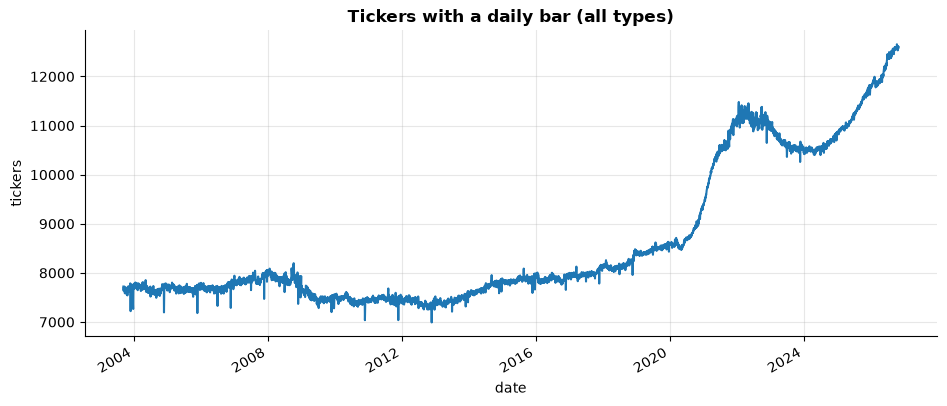

In [9]:
with timed("tickers per day, full daily history"):
    per_day = store.scan("bars_day").group_by("date").agg(pl.col("ticker").n_unique().alias("tickers")).sort("date").collect()

ax = per_day.to_pandas().set_index("date")["tickers"].plot(title="Tickers with a daily bar (all types)")
ax.set_ylabel("tickers");

## When data is missing

Tick data (trades and quotes) is only downloaded on request, because each full day is 3–10 GB
compressed. Queries warn when the stored data does not cover what was asked, and the warning
includes the exact command to fetch it:

In [10]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    t = store.trades("NVDA", start="2026-10-30")
print(f"rows returned: {t.height}")
for w in caught:
    print("warning:", w.message)

rows returned: 0


The CLI does the downloading (run these in a terminal):

```bash
uv run subspace status                                        # same table as coverage()
uv run subspace backfill history --dataset trades --start 2026-10-30 --symbols NVDA
uv run subspace backfill rest news                            # refresh one REST dataset
uv run subspace sync                                          # what the daily service runs
```

Next: **01 · Daily bars**.